# Lecture 1 — Quantum Computation Basics (UnitaryLab companion)

This notebook demonstrates the concepts of Lecture 1 using the UnitaryLab simulator
(v1.1.4). It is a narrative teaching companion: run the cells top to bottom.

Contents:
1. A qubit, amplitudes, and measurement
2. Single-qubit gates
3. Two qubits, CNOT, and the Bell state
4. Arbitrary state and Bloch angles
5. The Bloch sphere (matplotlib helper)
6. Quantum teleportation
7. Your turn

In [1]:
import numpy as np
from unitarylab.core import Circuit

# Render matplotlib figures inline and headless (works under nbconvert --execute).
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
%matplotlib inline

## 1. A qubit, amplitudes, and measurement
Prepare $|+\rangle=(|0\rangle+|1\rangle)/\sqrt2$ and read off measurement probabilities.

In [2]:
qc = Circuit(1, name='plus')
qc.h(0)
res = qc.execute(backend='numpy', dtype=np.complex128)
print('state:', np.round(res.state, 3))
print('probabilities:', res.probabilities)

state: [0.707+0.j 0.707+0.j]
probabilities: {'0': 0.5, '1': 0.5}


## 2. Single-qubit gates
Check $X|0\rangle=|1\rangle$ and $HZH=X$ on $|0\rangle$.

In [3]:
qc = Circuit(1); qc.x(0)
print('X|0> =', np.round(qc.execute(backend='numpy').state, 3))
qc2 = Circuit(1); qc2.h(0); qc2.z(0); qc2.h(0)
print('HZH|0> =', np.round(qc2.execute(backend='numpy').state, 3), '(expect |1>)')

X|0> = [0.+0.j 1.+0.j]
HZH|0> = [0.+0.j 1.+0.j] (expect |1>)


## 3. Two qubits, CNOT, and the Bell state
$|B^+\rangle=(|00\rangle+|11\rangle)/\sqrt2$ shows perfectly correlated outcomes.

In [4]:
qc = Circuit(2, name='Bell'); qc.h(0); qc.cx(0, 1)
res = qc.execute(backend='numpy', dtype=np.complex128)
print('state:', np.round(res.state, 3))
print('probabilities:', res.probabilities)
assert abs(res.probabilities.get('00', 0) - 0.5) < 1e-9 and abs(res.probabilities.get('11', 0) - 0.5) < 1e-9
print('Bell correlations verified.')

state: [0.707+0.j 0.   +0.j 0.   +0.j 0.707+0.j]
probabilities: {'00': 0.5, '11': 0.5}
Bell correlations verified.


### Drawing the circuit

`Circuit.draw(title=...)` returns a Matplotlib figure, so a circuit renders inline like any plot. Here is the Bell-state preparation circuit — a Hadamard on qubit 0 followed by a CNOT controlled on qubit 0.

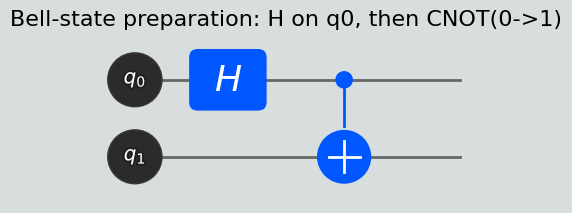

In [5]:
from IPython.display import display
bell = Circuit(2, name='Bell')
bell.h(0)
bell.cx(0, 1)
fig = bell.draw(title='Bell-state preparation: H on q0, then CNOT(0->1)')
display(fig)

## 4. Arbitrary state and Bloch angles
Load $\cos(\theta/2)|0\rangle+e^{i\varphi}\sin(\theta/2)|1\rangle$ and recover $(\theta,\varphi)$.

In [6]:
theta, phi = np.pi/3, np.pi/4
vec = np.array([np.cos(theta/2), np.exp(1j*phi)*np.sin(theta/2)], dtype=complex)
qc = Circuit(1); qc.initialize(vec, target=[0])
s = qc.execute(backend='numpy', dtype=np.complex128).state
th = 2*np.arccos(abs(s[0])); ph = np.angle(s[1]) - np.angle(s[0])
print('recovered theta,phi =', round(th, 4), round(ph, 4), '(expected', round(theta, 4), round(phi, 4), ')')
assert abs(th - theta) < 1e-6 and abs(ph - phi) < 1e-6
print('Bloch angles recovered.')

recovered theta,phi = 1.0472 0.7854 (expected 1.0472 0.7854 )
Bloch angles recovered.


## 5. The Bloch sphere
A pure single-qubit state $|\psi\rangle=a|0\rangle+b|1\rangle$ corresponds to a point on the
unit sphere with coordinates given by the Pauli expectation values
$(\langle X\rangle,\langle Y\rangle,\langle Z\rangle)$. For $|\psi\rangle=[a,b]$:

$$\langle X\rangle = 2\,\mathrm{Re}(\bar a\,b),\quad
\langle Y\rangle = 2\,\mathrm{Im}(\bar a\,b),\quad
\langle Z\rangle = |a|^2-|b|^2.$$

UnitaryLab has no Bloch-sphere plotter, so we build one with matplotlib.

In [7]:
def bloch_vector(state):
    """Return (<X>,<Y>,<Z>) for a single-qubit statevector [a, b]."""
    a, b = state[0], state[1]
    x = 2*np.real(np.conj(a)*b)
    y = 2*np.imag(np.conj(a)*b)
    z = np.abs(a)**2 - np.abs(b)**2
    return np.array([x, y, z], dtype=float)


def plot_bloch(vec, title=""):
    """Draw a translucent unit sphere with x/y/z axes and the state as an arrow."""
    fig = plt.figure(figsize=(4, 4))
    ax = fig.add_subplot(111, projection='3d')

    # translucent wireframe sphere
    u = np.linspace(0, 2*np.pi, 30)
    v = np.linspace(0, np.pi, 20)
    xs = np.outer(np.cos(u), np.sin(v))
    ys = np.outer(np.sin(u), np.sin(v))
    zs = np.outer(np.ones_like(u), np.cos(v))
    ax.plot_surface(xs, ys, zs, color='c', alpha=0.08, linewidth=0)
    ax.plot_wireframe(xs, ys, zs, color='gray', alpha=0.15, linewidth=0.4)

    # coordinate axes
    for a_, lbl in [((1, 0, 0), 'x'), ((0, 1, 0), 'y'), ((0, 0, 1), 'z')]:
        ax.plot([0, a_[0]], [0, a_[1]], [0, a_[2]], color='k', linewidth=0.8)
        ax.text(1.15*a_[0], 1.15*a_[1], 1.15*a_[2], lbl, fontsize=11)

    # state arrow from origin
    ax.quiver(0, 0, 0, vec[0], vec[1], vec[2], color='red', linewidth=2.5,
              arrow_length_ratio=0.12)

    ax.set_xlim([-1, 1]); ax.set_ylim([-1, 1]); ax.set_zlim([-1, 1])
    ax.set_box_aspect((1, 1, 1))
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
    plt.tight_layout()
    plt.show()

Build several states with UnitaryLab, read them out via `res.state`, and inspect their
Bloch vectors. Correctness is checked with asserts on $|0\rangle$ and $|+\rangle$.

In [8]:
def statevec(gates):
    qc = Circuit(1)
    for g in gates:
        g(qc)
    return qc.execute(backend='numpy', dtype=np.complex128).state

theta, phi = np.pi/3, np.pi/4
psi = np.array([np.cos(theta/2), np.exp(1j*phi)*np.sin(theta/2)], dtype=complex)

states = {
    '|0>':  statevec([]),
    '|1>':  statevec([lambda q: q.x(0)]),
    '|+>':  statevec([lambda q: q.h(0)]),
    '|->':  statevec([lambda q: q.x(0), lambda q: q.h(0)]),
    '|i>':  statevec([lambda q: q.h(0), lambda q: q.s(0)]),
    '(pi/3, pi/4)': statevec([lambda q: q.initialize(psi, target=[0])]),
}

for name, st in states.items():
    print(f'{name:>14}: state={np.round(st, 3)}  bloch={np.round(bloch_vector(st), 3)}')

# correctness checks
assert np.allclose(bloch_vector(states['|0>']), [0, 0, 1], atol=1e-9)
assert np.allclose(bloch_vector(states['|+>']), [1, 0, 0], atol=1e-9)
assert np.allclose(bloch_vector(states['|i>']), [0, 1, 0], atol=1e-9)
print('\nBloch-vector checks passed.')

           |0>: state=[1.+0.j 0.+0.j]  bloch=[0. 0. 1.]
           |1>: state=[0.+0.j 1.+0.j]  bloch=[ 0.  0. -1.]
           |+>: state=[0.707+0.j 0.707+0.j]  bloch=[1. 0. 0.]
           |->: state=[ 0.707+0.j -0.707+0.j]  bloch=[-1.  0.  0.]
           |i>: state=[0.707+0.j    0.   +0.707j]  bloch=[0. 1. 0.]
  (pi/3, pi/4): state=[0.866+0.j    0.354+0.354j]  bloch=[0.612 0.612 0.5  ]

Bloch-vector checks passed.


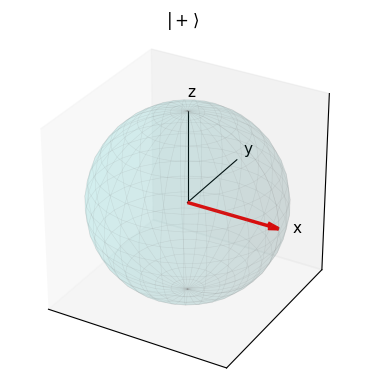

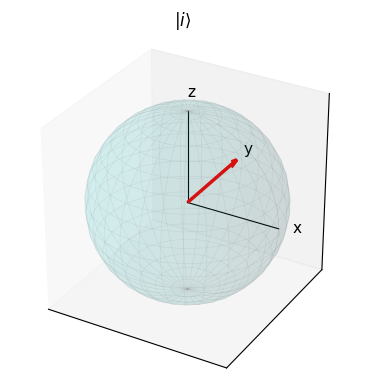

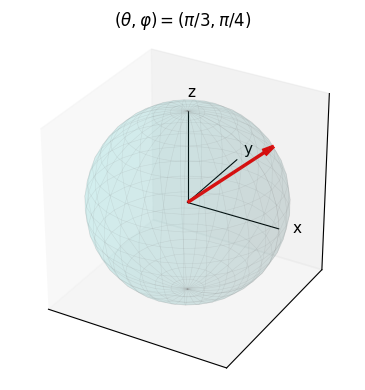

In [9]:
# Render a couple of spheres.
plot_bloch(bloch_vector(states['|+>']), title=r'$|+\rangle$')
plot_bloch(bloch_vector(states['|i>']), title=r'$|i\rangle$')
plot_bloch(bloch_vector(states['(pi/3, pi/4)']), title=r'$(\theta,\varphi)=(\pi/3,\pi/4)$')

## 6. Quantum teleportation
Alice teleports an unknown one-qubit state on qubit 0 to Bob's qubit 2, using a shared
Bell pair on qubits 1--2 and two classical bits. We simulate this coherently with the
statevector: after Alice's $\mathrm{CNOT}_{0\to1}$ and $H_0$, we condition on each of the
four measurement outcomes $(m_0,m_1)$, apply Bob's Pauli correction $Z^{m_0}X^{m_1}$, and
verify the recovered state matches the original with fidelity 1.

Note UnitaryLab orders qubit 0 as the least-significant bit, so the statevector reshapes as
`[q2, q1, q0]`.

In [10]:
rng = np.random.default_rng(7)
tt, pp = rng.uniform(0, np.pi), rng.uniform(0, 2*np.pi)
psi_in = np.array([np.cos(tt/2), np.exp(1j*pp)*np.sin(tt/2)], dtype=complex)
print('state to teleport:', np.round(psi_in, 4))

qc = Circuit(3, name='teleport')
qc.initialize(psi_in, target=[0])   # unknown state on q0
qc.h(1); qc.cx(1, 2)                 # Bell pair on q1, q2
qc.cx(0, 1); qc.h(0)                 # Alice entangles and rotates
state = qc.execute(backend='numpy', dtype=np.complex128).state.reshape(2, 2, 2)  # [q2,q1,q0]

X = np.array([[0, 1], [1, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)

print('\n  (m0,m1)   prob    fidelity')
for m0 in (0, 1):
    for m1 in (0, 1):
        branch = state[:, m1, m0]                 # Bob's (q2) amplitudes for this outcome
        prob = np.vdot(branch, branch).real
        bob = branch / np.linalg.norm(branch)
        corr = np.linalg.matrix_power(Z, m0) @ np.linalg.matrix_power(X, m1)
        bob = corr @ bob                          # apply feed-forward correction
        fid = abs(np.vdot(psi_in, bob))**2
        print(f'   ({m0},{m1})    {prob:.4f}   {fid:.6f}')
        assert abs(prob - 0.25) < 1e-9
        assert abs(fid - 1.0) < 1e-9
print('\nTeleportation verified: fidelity 1 for all four outcomes.')

state to teleport: [0.5554+0.j     0.6641-0.5005j]

  (m0,m1)   prob    fidelity
   (0,0)    0.2500   1.000000
   (0,1)    0.2500   1.000000
   (1,0)    0.2500   1.000000
   (1,1)    0.2500   1.000000

Teleportation verified: fidelity 1 for all four outcomes.


### Circuit diagram: teleportation

The full teleportation circuit built above: load the unknown state on q0, create a Bell pair on q1--q2, then Alice's CNOT and Hadamard (measurements and feed-forward corrections are applied classically afterward).

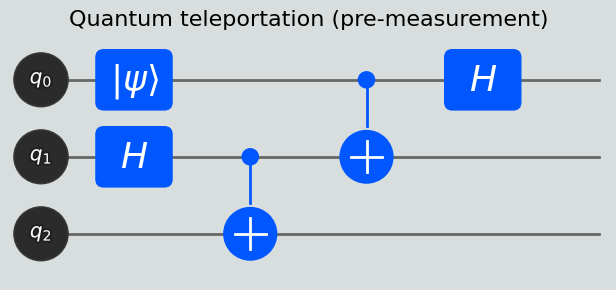

In [11]:
from IPython.display import display
tele = Circuit(3, name='teleport')
tele.initialize(psi_in, target=[0])   # unknown state on q0 (psi_in from the cell above)
tele.h(1); tele.cx(1, 2)               # Bell pair on q1, q2
tele.cx(0, 1); tele.h(0)               # Alice entangles and rotates
fig = tele.draw(title='Quantum teleportation (pre-measurement)')
display(fig)

## 7. Your turn
- Re-create $|-\rangle$ and verify $\langle +|-\rangle=0$.
- Build the other three Bell states and plot the reduced single-qubit Bloch vector (it
  should sit at the origin -- maximally mixed).
- Redo teleportation with a different random state and confirm fidelity 1.
See the Lecture 1 exercises (teleportation, superdense coding, CHSH).